# **About Dataset**
## **Context**
This Online Retail II data set contains all the transactions occurring for a UK-based and registered, non-store online retail between 01/12/2009 and 09/12/2011.The company mainly sells unique all-occasion gift-ware. Many customers of the company are wholesalers.

## **Content**
### **Attribute Information:**
**InvoiceNo:** Invoice number. Nominal. A 6-digit integral number uniquely assigned to each transaction. If this code starts with the letter 'c', it indicates a cancellation.

**StockCode:** Product (item) code. Nominal. A 5-digit integral number uniquely assigned to each distinct product.

**Description:** Product (item) name. Nominal.

**Quantity**: The quantities of each product (item) per transaction. Numeric.

**InvoiceDate:** Invice date and time. Numeric. The day and time when a transaction was generated.

**UnitPrice**: Unit price. Numeric. Product price per unit in sterling (Â£).

**CustomerID:** Customer number. Nominal. A 5-digit integral number uniquely assigned to each customer.

**Country:** Country name. Nominal. The name of the country where a customer resides.


# **Data loading and initial inspection**

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

### **Loding the Dataset**

In [7]:
df = pd.read_csv('online_retail_II.csv')

### **Inspecting the last and first records**

In [8]:
df.head()
df.tail()
df.sample(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
269997,515507,22668,PINK BABY BUNTING,5,2010-07-13 11:30:00,2.95,15039.0,United Kingdom
414799,529009,84970L,SINGLE HEART ZINC T-LIGHT HOLDER,12,2010-10-26 11:36:00,0.95,16962.0,United Kingdom
306643,519275,21929,JUMBO BAG PINK VINTAGE PAISLEY,100,2010-08-16 10:17:00,1.65,16029.0,United Kingdom
370556,525171,47367B,PAIR PADDED HANGERS PINK CHECK,1,2010-10-04 12:19:00,3.75,16414.0,United Kingdom
411913,C528756,82494L,WOODEN FRAME ANTIQUE WHITE,-1,2010-10-24 15:25:00,2.95,13564.0,United Kingdom
373535,525447,22602,CHRISTMAS RETROSPOT HEART WOOD,2,2010-10-05 13:57:00,0.85,16348.0,United Kingdom
407441,528382,90192,JADE DROP EARRINGS W FILIGREE,1,2010-10-21 18:01:00,5.09,NaN,United Kingdom
79911,496651,84450A,PINK RABBIT SITTING EASTER,4,2010-02-03 12:21:00,0.42,13553.0,United Kingdom
96841,498513,22274,FELTCRAFT DOLL EMILY,6,2010-02-19 12:07:00,2.95,17145.0,United Kingdom
188284,507259,47590B,PINK HAPPY BIRTHDAY BUNTING,15,2010-05-07 12:11:00,5.45,15738.0,United Kingdom


### **Understanding Dataset Dimension and structure**

In [9]:
df.shape #rows & columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 482436 entries, 0 to 482435
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      482436 non-null  object 
 1   StockCode    482436 non-null  object 
 2   Description  479632 non-null  object 
 3   Quantity     482436 non-null  int64  
 4   InvoiceDate  482435 non-null  object 
 5   Price        482435 non-null  float64
 6   Customer ID  386573 non-null  float64
 7   Country      482435 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 29.4+ MB


### **Data type & their unique values**

In [10]:
df.dtypes
df.nunique() #checking unique values


,0
Invoice,26766
StockCode,4604
Description,4641
Quantity,810
InvoiceDate,23543
Price,1535
Customer ID,4265
Country,40


### **Inspecting individual columns** (help to see all unique values)

In [11]:
df['Country'].unique()
df['Invoice'].unique()
df['StockCode'].unique()
df['InvoiceDate'].unique()

array(['2009-12-01 07:45:00', '2009-12-01 07:46:00',
       '2009-12-01 09:06:00', ..., '2010-11-23 13:01:00',
       '2010-11-23 13:02:00', nan], shape=(23544,), dtype=object)

### **Datatype Correction of incorrect data**

In [12]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce') #vonvert to standard datetime format
df['Customer ID'] = df['Customer ID'].astype('string') #it convert the the customer column in string datatype
df['Invoice'] = df['Invoice'].astype('string')
df['StockCode'] = df['StockCode'].astype('string')


In [13]:
#Checking Date range
df['InvoiceDate'].min()
df['InvoiceDate'].max()

Timestamp('2010-11-23 13:02:00')

#  **Data Cleaning & all**

In [14]:
#Calculating Missing Values
df.isnull().sum()

,0
Invoice,0
StockCode,0
Description,2804
Quantity,0
InvoiceDate,1
Price,1
Customer ID,95863
Country,1


In [15]:
#---Missing Percentage---
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_percentage.sort_values(ascending=False)

,0
Customer ID,19.870615
Description,0.581217
InvoiceDate,0.000207
Price,0.000207
Country,0.000207
Quantity,0.000000
Invoice,0.000000
StockCode,0.000000


### visualize missing values

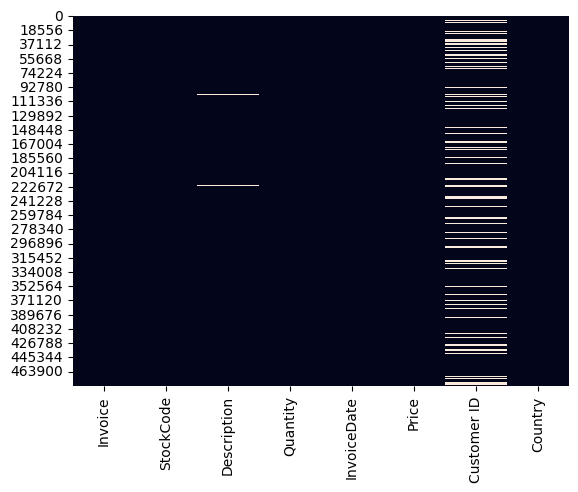

In [16]:
sns.heatmap(df.isnull(), cbar=False)
plt.show()

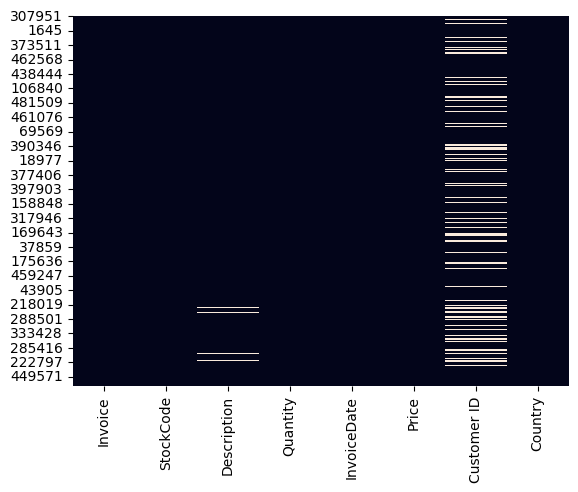

In [17]:
sns.heatmap(
    df.sample(1000).isnull(),
    cbar=False
)
plt.show()

### Questions on missing Customer IDs
* Which countries have the highest number of unidentified customers?



* Are unidentified customers associated with particular products?



* Are missing IDs concentrated in certain months?



* Do unidentified transactions have unusual quantities or prices?


### **Q1: Which countries have the highest number of unidentified customers?**

In [18]:
df['is_missing_cust'] = df['Customer ID'].isna()

country_missing = (
    df.groupby('Country')['is_missing_cust']
    .agg(Total_Transactions='count', Missing_Customer_IDs='sum')
    .assign(Missing_Percentage=lambda x: (x['Missing_Customer_IDs'] / x['Total_Transactions']) * 100)
    .sort_values('Missing_Customer_IDs', ascending=False)
)

display(country_missing.head(10))

,Total_Transactions,Missing_Customer_IDs,Missing_Percentage
Country,,,
United Kingdom,445348,94488,21.216667
EIRE,9372,913,9.741784
United Arab Emirates,432,114,26.388889
Hong Kong,76,76,100.000000
Bahrain,107,65,60.747664
France,5278,62,1.174687
RSA,111,46,41.441441
Bermuda,34,34,100.000000
Unspecified,289,30,10.380623


### **Q2: Are unidentified customers associated with particular products?**

In [19]:
# Filter for missing customer IDs and check the most frequent product descriptions
missing_cust_df = df[df['is_missing_cust']]
top_missing_products = missing_cust_df['Description'].value_counts().head(15).reset_index()
top_missing_products.columns = ['Description', 'Missing_ID_Transaction_Count']

display(top_missing_products)

,Description,Missing_ID_Transaction_Count
0,DOTCOM POSTAGE,698
1,REGENCY CAKESTAND 3 TIER,310
2,STRAWBERRY CERAMIC TRINKET BOX,287
3,PARTY BUNTING,286
4,WHITE HANGING HEART T-LIGHT HOLDER,283
5,PACK OF 72 RETRO SPOT CAKE CASES,252
6,ANTIQUE SILVER TEA GLASS ETCHED,213
7,RECYCLING BAG RETROSPOT,210
8,PACK OF 60 PINK PAISLEY CAKE CASES,209
9,JUMBO STORAGE BAG SUKI,207


### **Q3: Are missing IDs concentrated in certain months?**

In [20]:
# Extract Year-Month
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

# Group by month and calculate the percentage of missing customer IDs
monthly_missing = df.groupby('YearMonth')['is_missing_cust'].agg(['count', 'sum']).rename(columns={'count': 'Total_Transactions', 'sum': 'Missing_Customer_IDs'})
monthly_missing['Missing_Percentage'] = (monthly_missing['Missing_Customer_IDs'] / monthly_missing['Total_Transactions']) * 100

display(monthly_missing)

,Total_Transactions,Missing_Customer_IDs,Missing_Percentage
YearMonth,,,
2009-12,45228,13468,29.778014
2010-01,31555,9116,28.889241
2010-02,29388,5482,18.653872
2010-03,41511,8397,20.228373
2010-04,34057,6224,18.275244
2010-05,35323,5719,16.190584
2010-06,39983,8033,20.091039
2010-07,33383,5637,16.885840
2010-08,33306,6364,19.107668


### **Q4: Do unidentified transactions have unusual quantities or prices?**

In [21]:
# Compare descriptive statistics of Quantity and Price between identified and unidentified customers
comparison = df.groupby('is_missing_cust')[['Quantity', 'Price']].describe()
display(comparison.transpose())

is_missing_cust          False         True 
Quantity count   386573.000000  95863.000000
         mean        12.986230      0.736708
         std        103.440051    135.947044
         min      -7128.000000  -9600.000000
         25%          2.000000      1.000000
         50%          5.000000      1.000000
         75%         12.000000      2.000000
         max      19152.000000  10200.000000
Price    count   386573.000000  95862.000000
         mean         3.950176      7.245503
         std         73.912101    294.031000
         min          0.000000 -53594.360000
         25%          1.250000      1.660000
         50%          1.950000      3.360000
         75%          3.750000      5.910000
         max      25111.090000  25111.090000

### **Analyzing Cancellations & Negative Quantities**
In retail datasets, negative values in `Quantity` usually indicate cancelled transactions or returns. Often, cancelled invoice numbers start with the letter 'C'. verifying this and checking the proportion of cancellations.

In [33]:
# invoices with negative quantities start with 'C'
df['is_cancelled'] = df['Invoice'].str.startswith('C', na=False)

cancel_summary = df.groupby('is_cancelled')['Quantity'].agg(['count', 'min', 'max', 'mean'])
display(cancel_summary)

# Proportion of cancellations
cancel_pct = (df['is_cancelled'].sum() / len(df)) * 100
print(f"Percentage of cancelled/returned transactions: {cancel_pct:.2f}%")

,count,min,max,mean
is_cancelled,,,,
False,472923,-9600,19152,11.174324
True,9513,-7128,1,-20.376958


Percentage of cancelled/returned transactions: 1.97%


### **Pricing & Revenue Analysis**
checking for transactions with zero or negative prices (which could represent adjustments, bad debts, or gifts) and calculate the overall sales distribution.

In [28]:
# Inspect non-positive prices
zero_or_negative_prices = df[df['Price'] <= 0]
print(f"Number of transactions with Price <= 0: {len(zero_or_negative_prices)}")
print(zero_or_negative_prices['Description'].value_counts().head(10))

# Create a LineTotal column for revenue analysis (excluding cancellations for accurate revenue stats)
df['LineTotal'] = df['Quantity'] * df['Price']
valid_sales = df[~df['is_cancelled'] & (df['Quantity'] > 0) & (df['Price'] > 0)]

print(f"Total Revenue Generated: {valid_sales['LineTotal'].sum():,.2f}")

Number of transactions with Price <= 0: 3483
Description
?                               43
damaged                         38
damages                         37
missing                         24
checked                          8
OWL DOORSTOP                     7
POLYESTER FILLER PAD 45x45cm     7
given away                       6
FLAG OF ST GEORGE CAR FLAG       6
dotcom                           6
Name: count, dtype: int64
Total Revenue Generated: 9,492,431.46


### **Outlier Identification**
We will visualize the distribution of `Quantity` and `Price` using boxplots to identify extreme outliers.

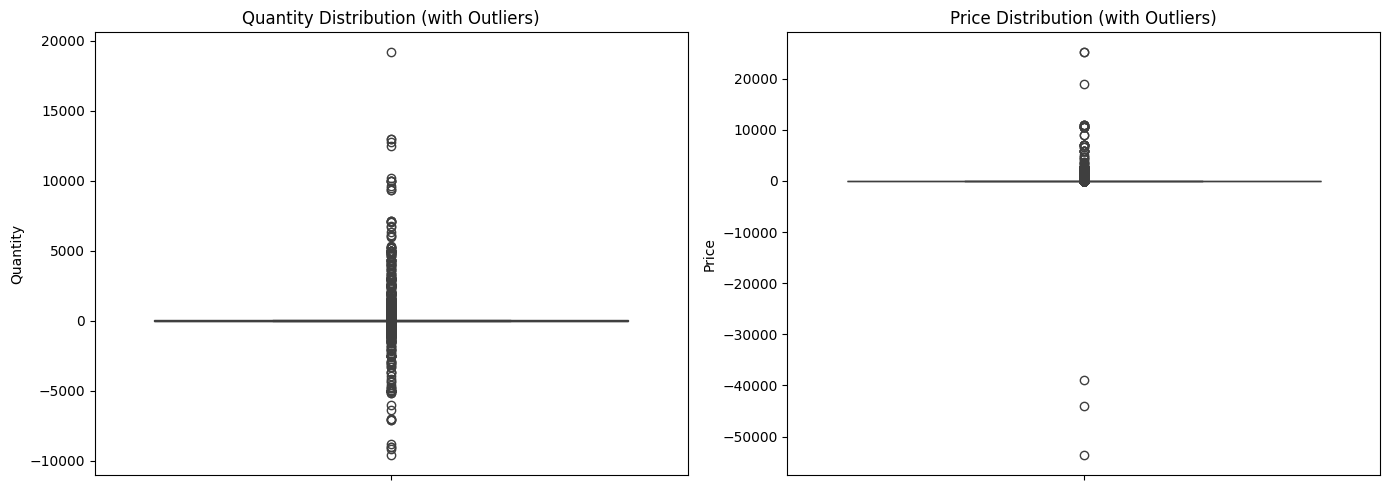

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, y='Quantity', ax=axes[0])
axes[0].set_title('Quantity Distribution (with Outliers)')

sns.boxplot(data=df, y='Price', ax=axes[1])
axes[1].set_title('Price Distribution (with Outliers)')

plt.tight_layout()
plt.show()

## **Investigating Extreme Outliers**
Let's filter and inspect the transactions with extremely high values of quantity or unit price to understand who these customers are or if they represent data logging anomalies.

In [30]:
# Show top 10 transactions with the largest absolute quantity
top_qty = df.iloc[df['Quantity'].abs().nlargest(10).index]
display(top_qty[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID', 'Country']])

# Show top 10 transactions with the highest unit price
top_price = df.nlargest(10, 'Price')
display(top_price[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID', 'Country']])

,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902.0,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902.0,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902.0,Denmark
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902.0,Denmark
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902.0,Denmark
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,0.00,<NA>,United Kingdom
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940.0,United Kingdom
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,17940.0,United Kingdom
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,17940.0,United Kingdom
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,0.25,17940.0,United Kingdom


,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
241824,C512770,M,Manual,-1,25111.09,17399.0,United Kingdom
241827,512771,M,Manual,1,25111.09,<NA>,United Kingdom
320581,C520667,BANK CHARGES,Bank Charges,-1,18910.69,<NA>,United Kingdom
135012,C502262,M,Manual,-1,10953.50,12918.0,United Kingdom
135013,502263,M,Manual,1,10953.50,12918.0,United Kingdom
135014,C502264,M,Manual,-1,10953.50,12918.0,United Kingdom
135015,502265,M,Manual,1,10953.50,<NA>,United Kingdom
342135,C522793,M,Manual,-1,10468.80,14063.0,United Kingdom
342147,522796,M,Manual,1,10468.80,<NA>,United Kingdom
358639,524159,M,Manual,1,10468.80,14063.0,United Kingdom


## **Monthly Revenue Trends**
To understand the business growth cycle, we will group our valid sales transactions by month and plot the monthly total revenue trend.

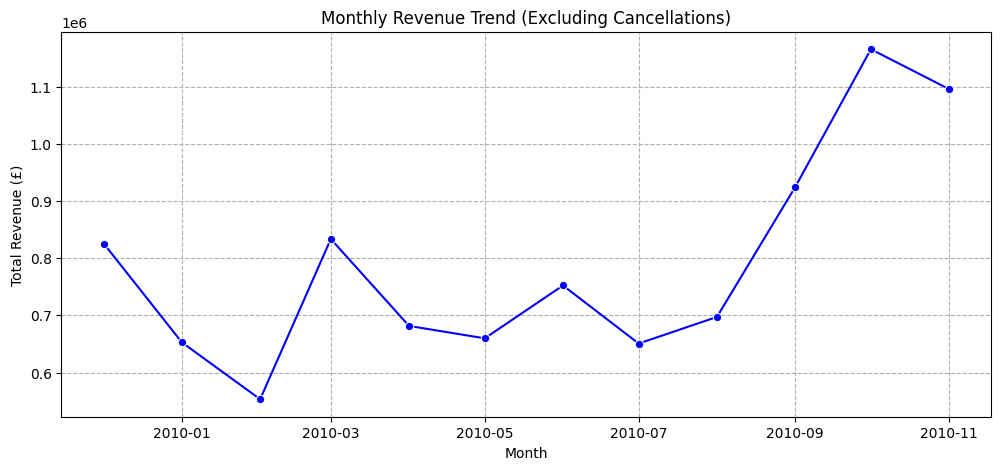

In [31]:
# Group valid sales by Year-Month and calculate sum of LineTotal
monthly_revenue = valid_sales.groupby('YearMonth')['LineTotal'].sum().reset_index()
monthly_revenue['YearMonth'] = monthly_revenue['YearMonth'].dt.to_timestamp()

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_revenue, x='YearMonth', y='LineTotal', marker='o', color='b')
plt.title('Monthly Revenue Trend (Excluding Cancellations)')
plt.xlabel('Month')
plt.ylabel('Total Revenue (£)')
plt.grid(True, linestyle='--')
plt.show()

## **1. Duplicate Row Analysis**

In [37]:
# 1. Duplicate Row Analysis
duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df)) * 100
print(f"--- DUPLICATION ANALYSIS ---")
print(f"Total Duplicate Rows Found: {duplicate_count:,}")
print(f"Percentage of Duplicate Rows: {duplicate_percentage:.2f}%\n")

# inspect a sample of duplicate records
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].sort_values(by=['Invoice', 'StockCode']).head(6))

--- DUPLICATION ANALYSIS ---
Total Duplicate Rows Found: 6,177
Percentage of Duplicate Rows: 1.28%



,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_missing_cust,YearMonth,is_cancelled,LineTotal
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,False,2009-12,False,1.95
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,False,2009-12,False,1.95
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False,2009-12,False,3.75
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False,2009-12,False,3.75
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False,2009-12,False,3.75
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,False,2009-12,False,3.75


### **2. Scanning for Test and Non-Product Stock Codes**
Retail databases often contain non-product entries (like postage, manual adjustments, samples, or developer tests) embedded in the `StockCode` or `Description` columns. We will identify the most frequent non-numeric stock codes.

In [38]:
# Get non-numeric stock codes (codes containing letters)
non_numeric_stock = df[df['StockCode'].str.contains('[A-Za-z]', na=False, regex=True)]

non_numeric_summary = (
    non_numeric_stock.groupby('StockCode')['Description']
    .unique()
    .to_frame()
    .join(non_numeric_stock['StockCode'].value_counts().to_frame(name='Occurrence_Count'))
    .sort_values(by='Occurrence_Count', ascending=False)
)

print("--- NON-PRODUCT OR SPECIAL TRANSACTION CODES ---")
display(non_numeric_summary.head(10))

--- NON-PRODUCT OR SPECIAL TRANSACTION CODES ---


,Description,Occurrence_Count
StockCode,,
85123A,"[WHITE HANGING HEART T-LIGHT HOLDER, 21733 mixed]",3283
85099B,"[JUMBO BAG RED WHITE SPOTTY , RED RETROSPOT JU...",1907
82494L,"[WOODEN FRAME ANTIQUE WHITE , MISSING, nan]",1079
85099F,[JUMBO BAG STRAWBERRY],1036
85099C,[JUMBO BAG BAROQUE BLACK WHITE],938
84970S,[HANGING HEART ZINC T-LIGHT HOLDER],880
POST,"[POSTAGE, nan]",805
M,[Manual],800
DOT,"[DOTCOM POSTAGE, nan]",699


### **3. Transaction Frequency per Customer (Concentration Risk)**
To understand customer behavior, we need to inspect the purchasing power distribution. Do a few customers dominate the dataset, or is revenue evenly distributed?

--- CUSTOMER TRANSACTION CONCENTRATION ---
count       4265.0
mean     90.638453
std      194.72442
min            1.0
25%           18.0
50%           43.0
75%           97.0
max         5496.0
Name: Transaction_Count, dtype: Float64


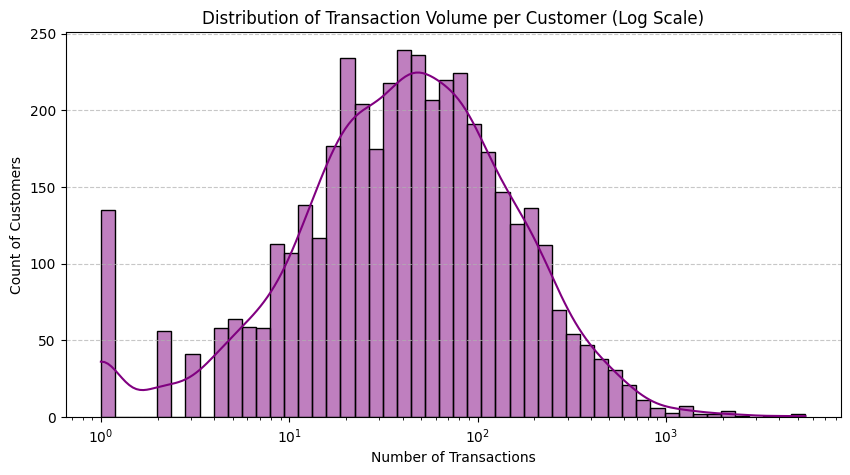

In [39]:
# Analyze purchase frequency by unique customers (excluding missing values)
customer_volume = df[df['Customer ID'].notna()]['Customer ID'].value_counts().reset_index()
customer_volume.columns = ['Customer ID', 'Transaction_Count']

print("--- CUSTOMER TRANSACTION CONCENTRATION ---")
print(customer_volume['Transaction_Count'].describe())

# Visualizing the distribution of transactions per customer (Log Scale to handle long tails)
plt.figure(figsize=(10, 5))
sns.histplot(customer_volume['Transaction_Count'], bins=50, kde=True, log_scale=True, color='purple')
plt.title('Distribution of Transaction Volume per Customer (Log Scale)')
plt.xlabel('Number of Transactions')
plt.ylabel('Count of Customers')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## **Top 10 Best Selling Products**
Let's determine which products generate the highest share of sales revenue.

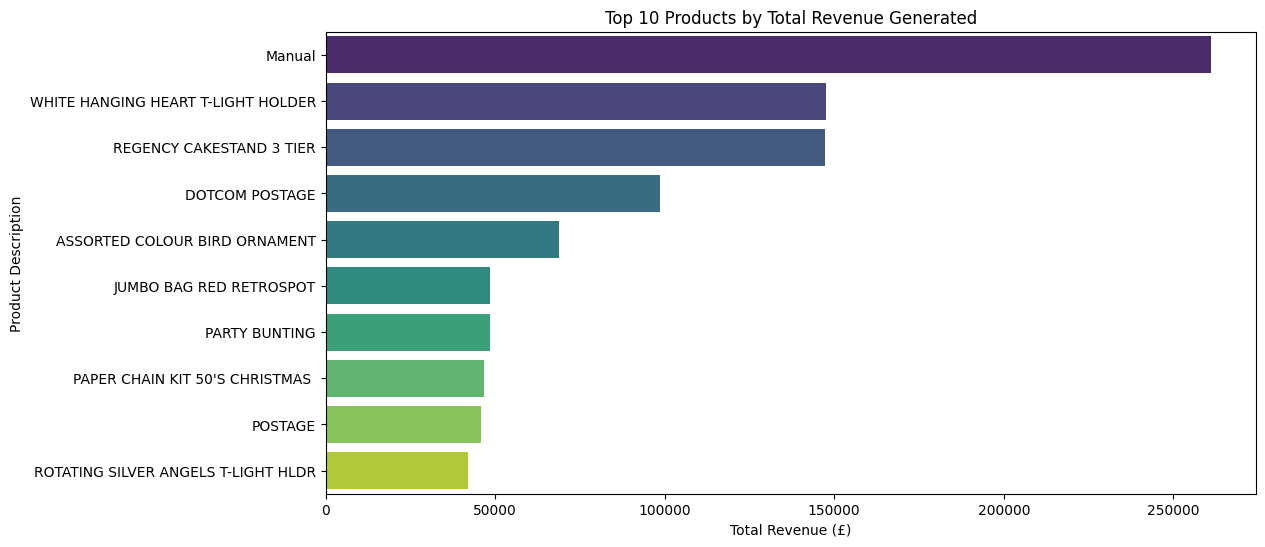

In [32]:
# Top 10 products by revenue
top_products = (
    valid_sales.groupby(['StockCode', 'Description'])['LineTotal']
    .sum()
    .reset_index()
    .sort_values(by='LineTotal', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_products, x='LineTotal', y='Description', palette='viridis')
plt.title('Top 10 Products by Total Revenue Generated')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Product Description')
plt.show()

In [44]:
df_processed.to_csv('online_retail_processed.csv', index=False)
print("Dataset saved to '/content/online_retail_processed.csv'")

Dataset saved to '/content/online_retail_processed.csv'


## **Key Insights & Executive Summary of the EDA**

Based on our comprehensive exploratory data analysis of the retail dataset, here are the main findings and anomalies discovered:

### **1. Missing Customer Identifiers**
* **Magnitude**: Approximately **19.87%** of transactions do not have a recorded `Customer ID`.
* **Geographic Pattern**: These unidentified transactions are overwhelmingly concentrated in the **United Kingdom**, followed by **EIRE**.
* **Associated Products**: Unidentified transactions are highly associated with service items like **'DOTCOM POSTAGE'** and **'Manual'** entries.

### **2. Cancellations & Returns**
* **Cancellations**: Cancelled orders (indicated by Invoice numbers starting with **'C'**) make up **1.97%** of all transactions.
* **Impact**: Returned items show massive negative quantities (reaching as low as **-7,128** units), which skew average order sizes if not isolated.

### **3. Irregular Prices & Non-Sales Transactions**
* **Zero & Negative Prices**: There are **3,483** transactions with a price of zero or less. Their descriptions (e.g., `'damaged'`, `'missing'`, `'?'`, `'given away'`) indicate these are non-sales adjustment records, bad debt write-offs, or inventory corrections.
* **Manual Overhead**: The highest unit prices in the dataset belong to **'Manual'** overrides and **'BANK CHARGES'**, reaching up to **£25,111.09**.

### **4. Seasonal Trends & Top Sellers**
* **Seasonality**: Monthly revenue remains relatively stable around **£550k - £850k** during the year, but experiences a massive surge in **October (£1.16M)** and **November (£1.09M)** due to peak holiday shopping.
* **Top Revenue Drivers**: `'Manual'` booking charges, `'WHITE HANGING HEART T-LIGHT HOLDER'`, and `'REGENCY CAKESTAND 3 TIER'` are the top financial contributors to total revenue.

## **Top 5 Critical Questions Raised by This EDA**

Based on our exploratory findings, here are the most important business and data processing questions we must address before proceeding to modeling or advanced analytics:

1. **How should we treat transactions with missing Customer IDs?**  
   Since unidentified customers make up nearly **20%** of our data, should we isolate them into a separate group, impute them, or discard them depending on whether our goal is user-level recommendation or overall inventory forecasting?

2. **How do we handle 'Manual' overrides and bookkeeping entries?**  
   Transactions flagged with `'M'` (Manual) and `'BANK CHARGES'` dominate our high-price outlier list and top-revenue lists. Are these actual sales, or should they be excluded from consumer purchasing behavior models?

3. **Should we filter out extreme bulk orders or treat them as a distinct customer segment?**  
   We observed single transactions with quantities exceeding **10,000+** units. Do these represents B2B wholesale buyers that need to be modeled separately from typical retail consumers?

4. **What is the best way to handle cancellations and returns?**  
   Should we structurally pair and neutralize each cancelled transaction (invoices starting with `'C'`) with its original purchase record, or treat them as a continuous rate of return?

5. **What is causing the major revenue surge in October and November?**  
   Does this massive volume spike represent holiday seasonal shopping (Halloween/Christmas stock-up), and how should we adjust inventory levels to prevent stockouts during this high-demand period?